In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pygraphon.graphons.StepGraphon import StepGraphon
import numpy as np
from pygraphon.plots.plot_matrices import spy
import matplotlib.pyplot as plt
from pygraphon.utils.utils_graph import edge_density
from tqdm import tqdm

In [3]:
#Set the matrix of theta
graphon_matrix = np.array([[0.8,0.1,0.1],[0.1,0.8,0.1],[0.1,0.1,0.8]])
#set up normalised graphon with graphon
graphon = StepGraphon(graphon_matrix,1/3)

In [4]:
from pygraphon.graphons import graphon_log

In [5]:
#original integral and normalised one
print(graphon.integral(graphon_matrix), graphon.integral())

0.33333333333333337 1.0


In [6]:
#new graphon after normalisation
graphon.graphon

array([[2.4, 0.3, 0.3],
       [0.3, 2.4, 0.3],
       [0.3, 0.3, 2.4]])

In [7]:
from pygraphon.plots.plot_matrices import spy
import matplotlib.pyplot as plt

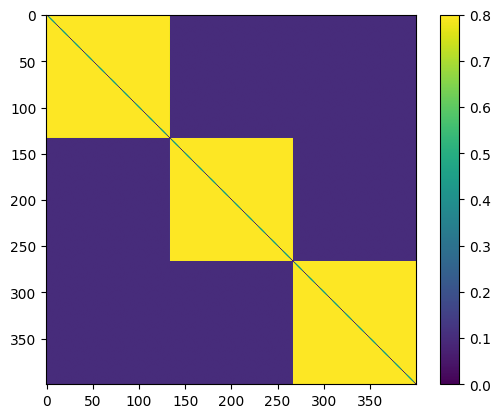

In [8]:
plt.imshow(graphon._get_edge_probabilities(400,False,True))
plt.colorbar()
plt.show()

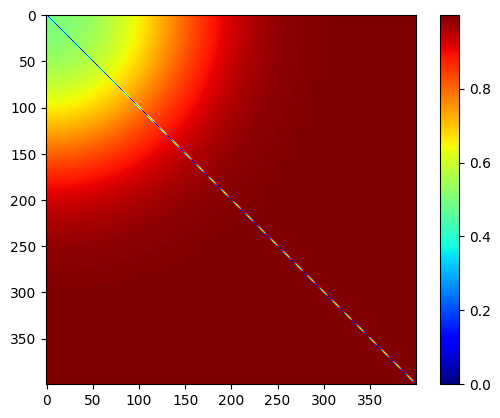

In [128]:
#Draw a graph from the graphon with a given density and number of vertices, see GraphonAbstract.py
from pygraphon.graphons import graphon_logit_sum
A = graphon.draw(rho = 1,n = 500, exchangeable=False)
plt.imshow(graphon_logit_sum._get_edge_probabilities(400,False,True), cmap = "jet")
plt.colorbar()
plt.show()

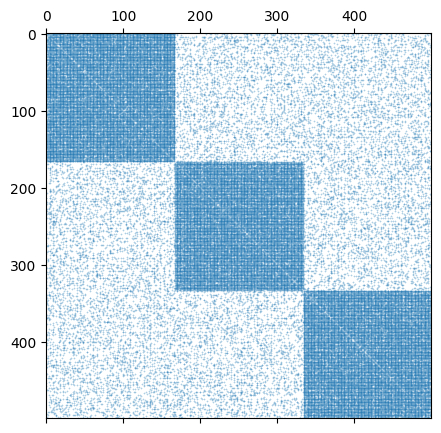

In [136]:
fig, ax = spy(A)#from pygraphon.plots.plot_matrices
plt.show()

In [86]:
edge_density(A)

0.9449058116232465

In [87]:
from pygraphon.estimators import SAS

In [88]:
estimator = SAS()
estimator.fit(graph = A)

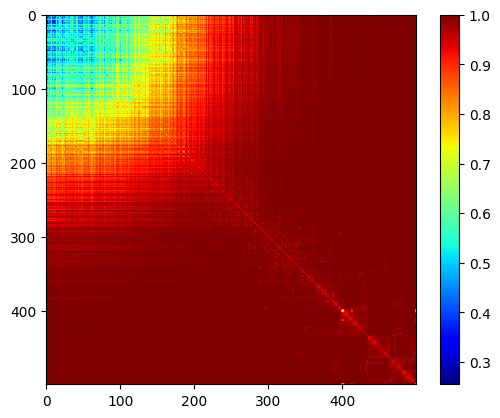

In [89]:
plt.imshow(estimator.get_edge_connectivity(), cmap = "jet")
plt.colorbar()

In [90]:
np.linalg.norm(estimator.get_edge_connectivity() - P)**2/(500**2)

0.001954548453038586

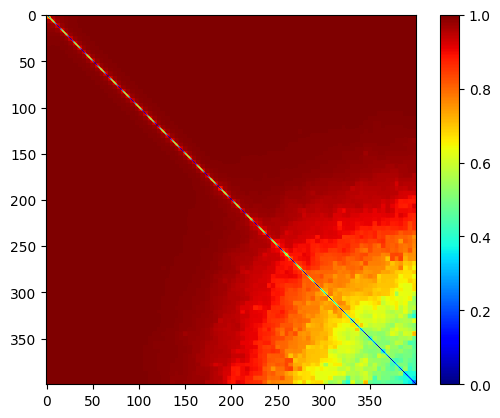

In [91]:
plt.imshow(estimator.get_graphon()._get_edge_probabilities(400,False,True), cmap = "jet")
plt.colorbar()

In [92]:
from pygraphon.estimators import HistogramEstimator, MomentEstimator, SimpleMomentEstimator

In [26]:
hist = HistogramEstimator()
hist.fit(graph= A, bandwidthHist= None)

[15 11 12 14 16 10  1  3  0  9]
Initial log-likelihood: -18059.133986325498
fast normalized ll: -0.14476259708477354
Initial normalized log-likelihood: -0.15412762640885463


LL: -0.1197,  4 global improvements: 100%|██████████| 20/20 [00:23<00:00,  1.16s/it]


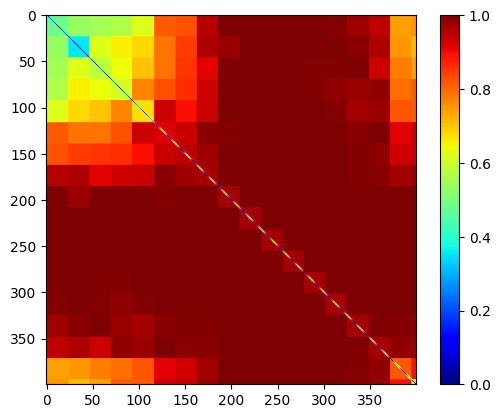

In [27]:
plt.imshow(hist.get_graphon()._get_edge_probabilities(400,False,True), cmap = "jet")
plt.colorbar()

In [40]:
from pygraphon.norm import MseProbaEdge
norm = MseProbaEdge(n_nodes = 500)
norm(graphon_logit_sum, hist)

0.003312149638564783

In [154]:
my_hist = HistogramEstimator()
my_hist.fit(graph= A, bandwidthHist= 0.3)

[150 150 150  50]


Likelihood: -0.3323, tol: 0, +: 498: 100%|██████████| 10/10 [00:03<00:00,  2.65it/s]


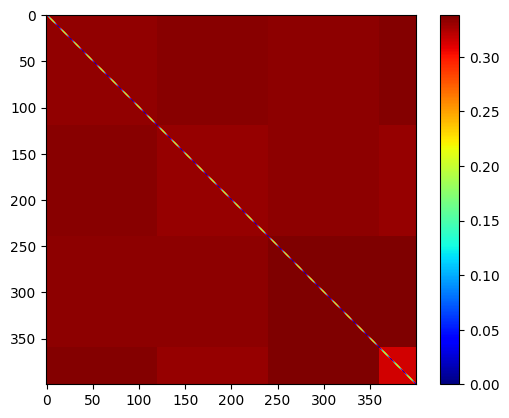

In [155]:
plt.imshow(my_hist.get_graphon()._get_edge_probabilities(400,False,True), cmap = "jet")
plt.colorbar()

In [143]:
from pygraphon.estimators.networkhistogram.nethist import nethist
best_assignment = nethist(A,int(A.shape[0]/3))

[166 166 166   2]


Likelihood: -0.1182, tol: 0, +: 314: 100%|██████████| 10/10 [00:03<00:00,  3.09it/s]


In [144]:
int(A.shape[0]/3)

166

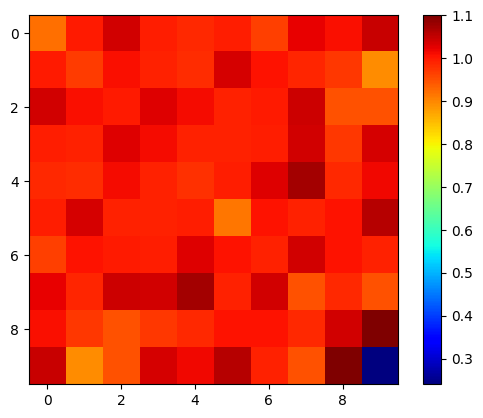

In [145]:
plt.imshow(my_hist.get_graphon().graphon, cmap = "jet")
plt.colorbar()

In [102]:
norm(graphon_logit_sum, my_hist)

0.012605417403579117

In [105]:
hist_full = HistogramEstimator()
hist_full.fit(graph= A, bandwidthHist= None)


Initial log-likelihood: -17009.947307682723
fast normalized ll: -0.1363522830275168
Initial normalized log-likelihood: -0.14430251285393014


LL: -0.0794,  4 global improvements:  46%|████▌     | 230/500 [04:14<04:58,  1.11s/it]

3 consecutive likelihood improvements less than specified tolerance; quitting now
Best LL: -0.0794


In [109]:
norm(graphon_logit_sum, hist_full)

0.02759625555737491

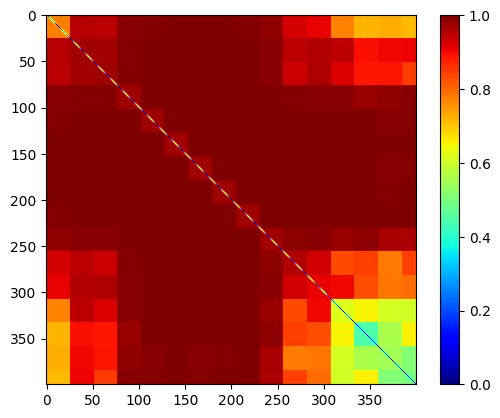

In [107]:
plt.imshow(hist_full.get_graphon()._get_edge_probabilities(400,False,True), cmap = "jet")
plt.colorbar()

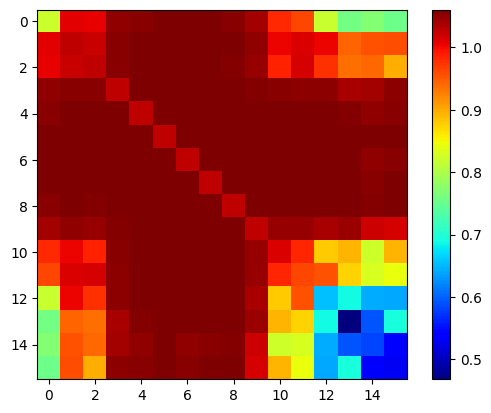

In [110]:
plt.imshow(hist_full.get_graphon().graphon, cmap = "jet")
plt.colorbar()

In [111]:
hist_full.get_graphon().graphon.shape

(16, 16)

In [76]:
from pygraphon.estimators.networkhistogram.nethist import _first_guess_blocks
from pygraphon.estimators.networkhistogram.graphest_fastgreedy import graphest_fastgreedy
from pygraphon.estimators.networkhistogram.greedy_readable import greedy_opt

n = A.shape[0]
rho = edge_density(A)
n_obs = int(n*(n-1)/2)
starting_labels = _first_guess_blocks(A,33,rho/4)

In [81]:
best_labels, bests, currents, overalls = greedy_opt(A, starting_labels, maxNumRestarts=50)

Likelihood: -0.0000:  54%|█████▍    | 27/50 [00:13<00:11,  2.05it/s]                 


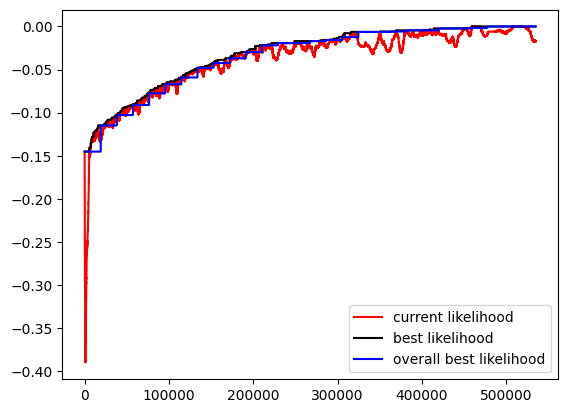

In [82]:
plt.plot(np.array(currents)/n_obs, label = "current likelihood", color = "red")
plt.plot(np.array(bests)/n_obs, label = "best likelihood", color = "black")
plt.plot(np.array(overalls)/n_obs, label = "overall best likelihood", color = "blue")
plt.legend()
plt.show()

In [ ]:
from pygraphon.estimators.networkhistogram.greedy_readable import xlogx, bernlikelihood, Assignment

In [ ]:
a = Assignment(starting_labels,A)

In [ ]:
a.likelihood

In [ ]:
best_labels, bests, currents = greedy_opt(A, starting_labels, maxNumRestarts=3)

In [ ]:
plt.plot(np.array(bests)/n_obs, label = "best likelihood", color = "red")
plt.plot(np.array(currents)/n_obs, label = "trial likelihood", color = "grey", alpha = 0.5)
plt.legend()
plt.show()

In [ ]:
a_mine = Assignment(best_labels,A)
a_matlab = Assignment(best_labels_matlab,A)

In [ ]:
print(a_mine.likelihood/n_obs, a_matlab.likelihood/n_obs)

In [ ]:
lls[-1]/n_obs

In [ ]:
lls[0]/n_obs

In [ ]:
best_labels_matlab, _, trace = graphest_fastgreedy(
            A=A, hbar=33, inputLabelVec=best_labels_matlab, verbose=True, trace=True, maxNumRestarts=10
        )
plt.plot(trace["best"], label = "best", color ="black")
plt.plot(trace["current"], label = "current", color = "red")
plt.plot(trace["trials"], label = "trials", alpha = 0.5, color ="gray")
plt.legend()
plt.show()

In [ ]:
trace["best"][-1]

In [ ]:
best_labels_matlab, _, trace = graphest_fastgreedy(
            A=A, hbar=33, inputLabelVec=best_labels_matlab, verbose=True, trace=True, maxNumRestarts=10
        )
starting_labels = best_labels_matlab
plt.plot(trace["best"], label = "best", color ="black")
plt.plot(trace["current"], label = "current", color = "red")
plt.plot(trace["trials"], label = "trials", alpha = 0.5, color ="gray")
plt.legend()
plt.show()

In [ ]:
trace["best"][0]

In [ ]:
from pygraphon.plots.plots_graphon import plot
plt.imshow(hist.get_edge_connectivity(), cmap="jet")
plt.colorbar()
plt.show()

In [ ]:
np.linalg.norm(hist.get_edge_connectivity() - P)**2/(500**2)

In [ ]:
plt.imshow(hist.get_graphon()._get_edge_probabilities(400,exchangeable = False), cmap = "jet")
plt.colorbar()

In [ ]:
from pygraphon.subgraph_isomorphism.CycleCount import CycleCount
counter = CycleCount(L = 9)

In [ ]:
momentestimator = SimpleMomentEstimator(3)
mome_simple_approx = momentestimator.estimate(adjacency_matrix= A)

In [ ]:
plot(mome_simple_approx)
plt.show()

In [ ]:
mome_simple_approx.graphon

In [ ]:
mome_simple_approx.integral()

Clustering the tiles independently (i.e. without structure)

In [ ]:
from sklearn.cluster import KMeans
#Extract tiles and reshape
nrow_tile = hist_epprox.graphon.shape[0]
flat_graphon = hist_epprox.graphon[np.triu_indices(nrow_tile)]
#Clustering according to kmeans
max_k = int(nrow_tile*(nrow_tile+1)/2)#number of individual tile
avr_graphon = [flat_graphon.copy() for k in range(max_k)]#copies for different number of clusters
for i in range(max_k-1):
    if i==0:
        avr_graphon[i]=edge_density(A)*np.ones_like(flat_graphon)
    else:
        kmeans = KMeans(n_clusters=i+1, random_state=0).fit(flat_graphon.reshape(-1,1))
        #Smooth using mean by memberhsip
        for j in range(i+1):
            avr_graphon[i][kmeans.labels_==j] = flat_graphon[kmeans.labels_==j].mean()